In [1]:
# !pip install pandas
# !pip install matplotlib.pyplot
# !pip install seaborn
# !pip install openpyxl

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
df:pd.DataFrame = pd.read_excel("ICB_DADOS_2026.xlsx")

In [5]:
df.columns

Index(['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco',
       'Quantidade', 'PPK'],
      dtype='str')

In [6]:
df_cafe = df[df['Produto'] == 'Café']
df_cafe = df_cafe.sort_values('Mes_Ano_Data')

df_pilao = df[df['Marca'] == 'Pilão']
df_3coracoes = df[df['Marca'] == '3 Corações']
df_caboclo = df[df['Marca'] == 'Caboclo']

x = np.array(df_caboclo['Mes_Ano_Data'])
y = np.array(df_caboclo['Preco'])

In [19]:
df_cafe['Marca'].unique()

array(['Pilão', '3 Corações', 'Caboclo', 'Pelé', 'Canecão', 'Moraes',
       'São Joaquim', 'Melita', 'Nescafé', 'São', 'Fort', 'União', nan,
       '3 corações', 'São Joaquim ', 'Outro'], dtype=object)

In [21]:
def plotar_grafico_por_cada_marca(df, marca:list):
    for m in marca:
        df_marca = df[df['Marca'] == m]
        plt.figure(figsize=(10, 6))
        sns.lineplot(data=df_marca, x='Mes_Ano_Data', y='Preco', marker='o')
        plt.title(f'Preço do Café - {m}')
        plt.xlabel('Mês/Ano')
        plt.ylabel('Preço')
        plt.xticks(rotation=45)
        plt.grid()
        plt.tight_layout()
        plt.show()

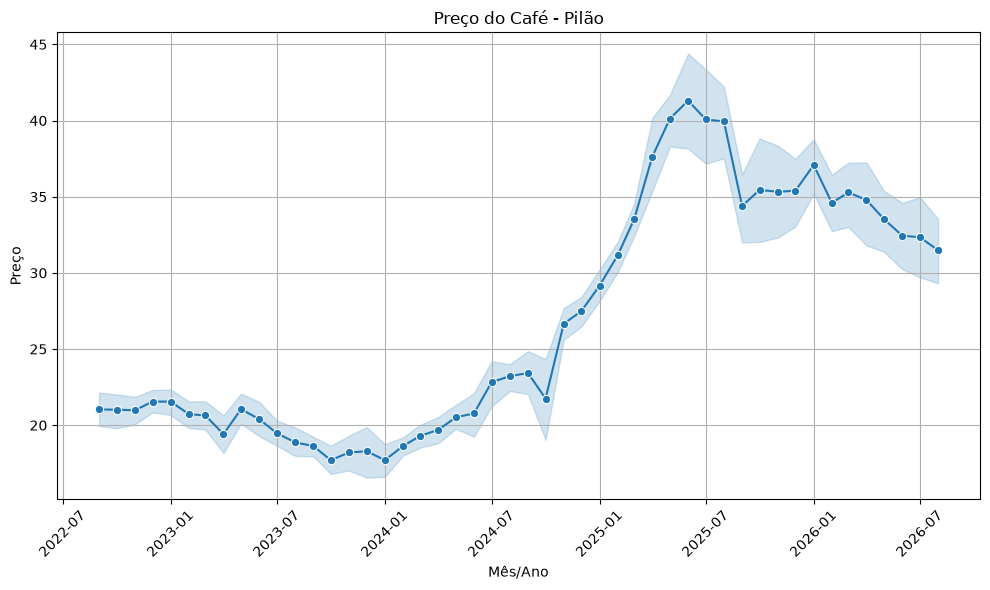

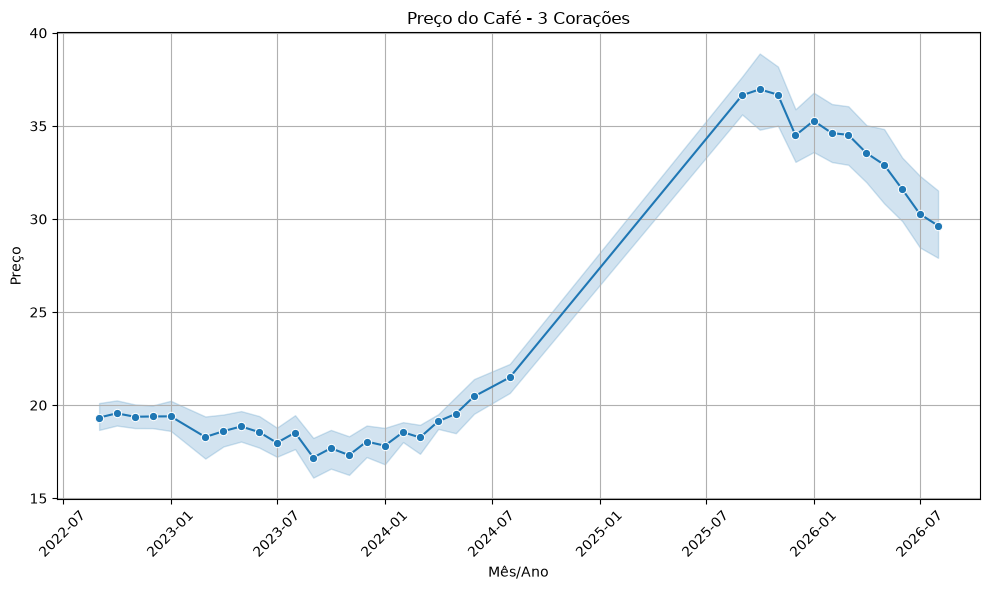

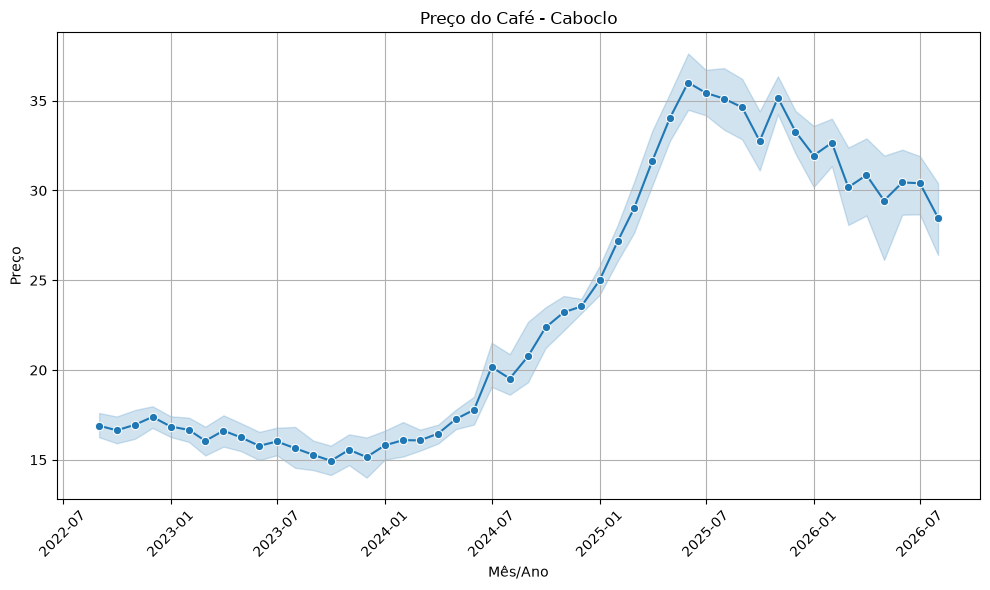

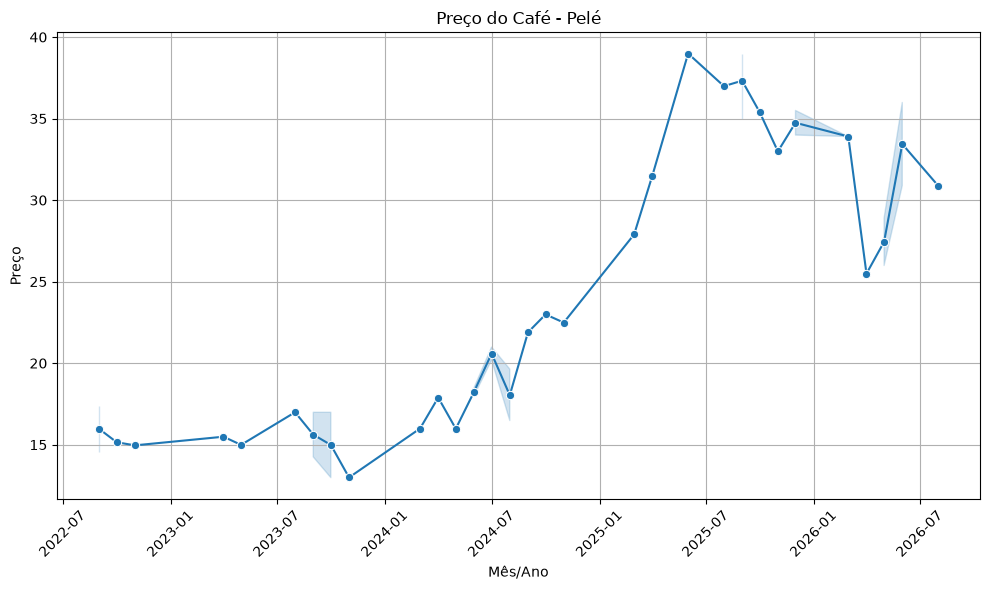

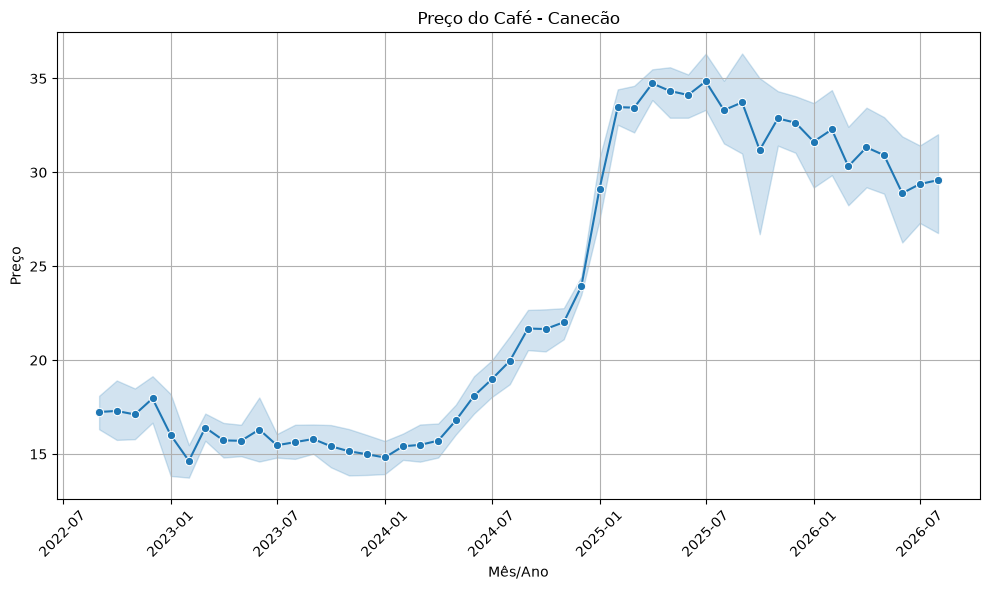

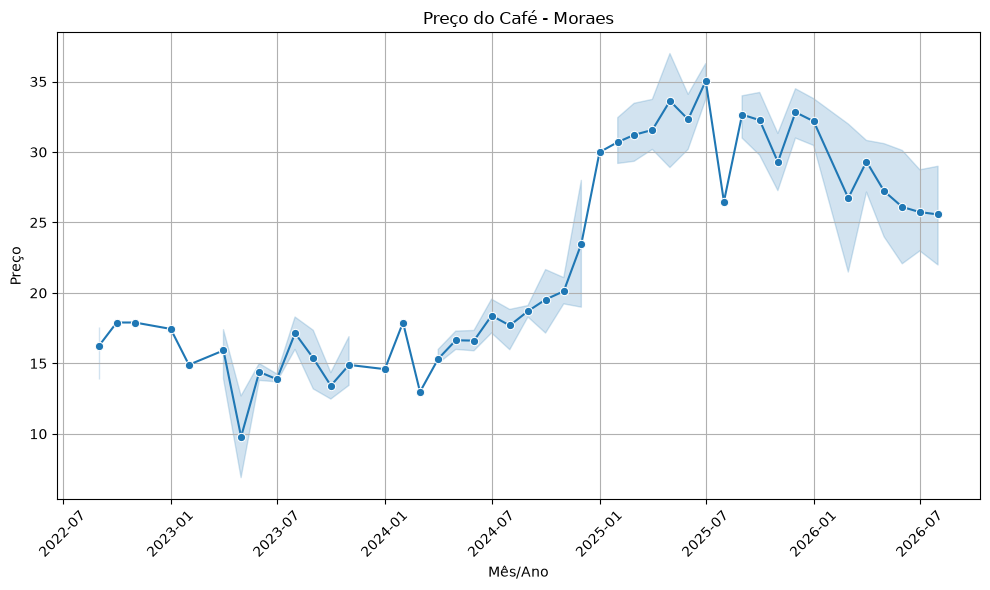

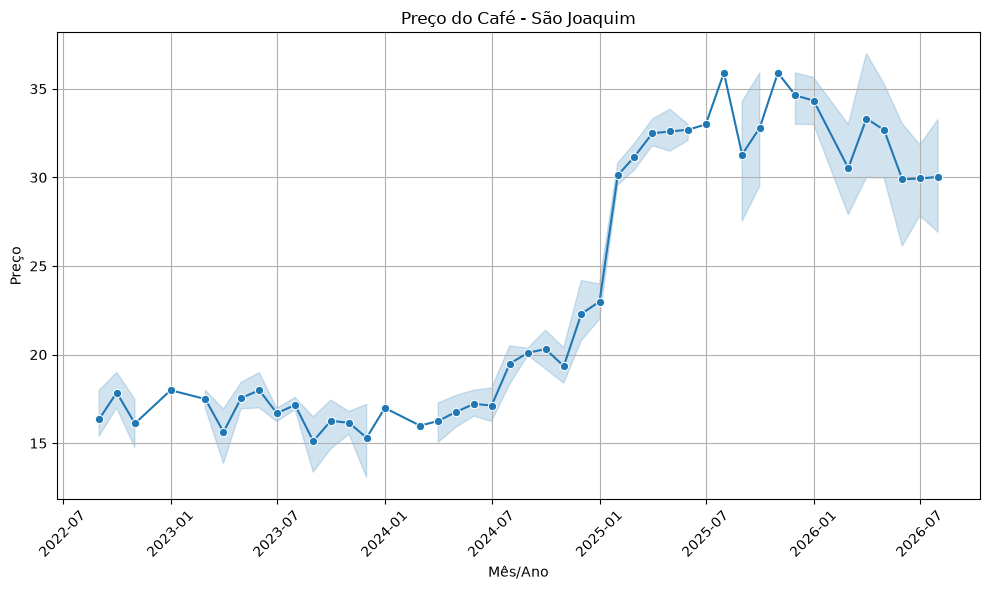

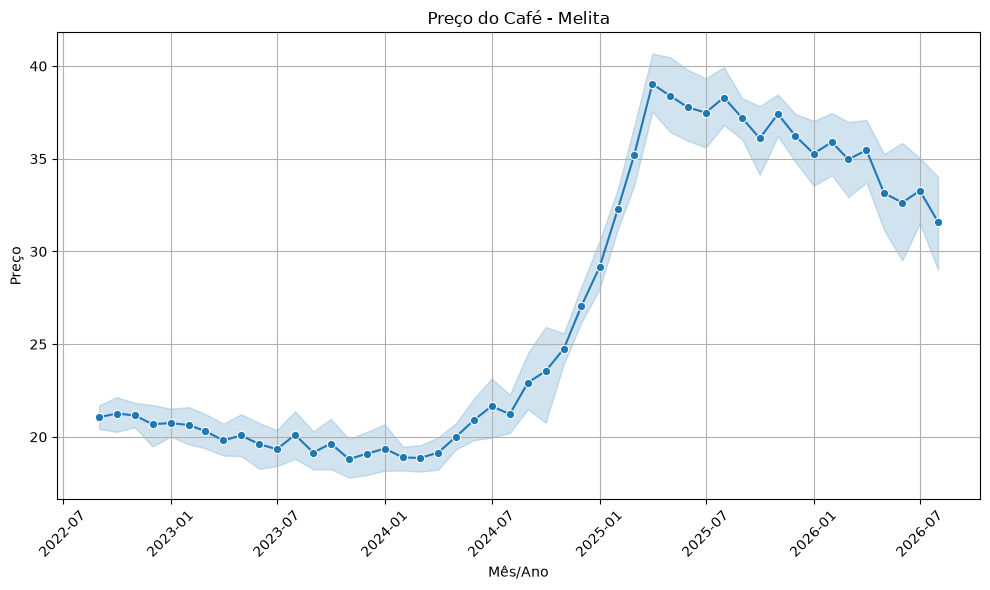

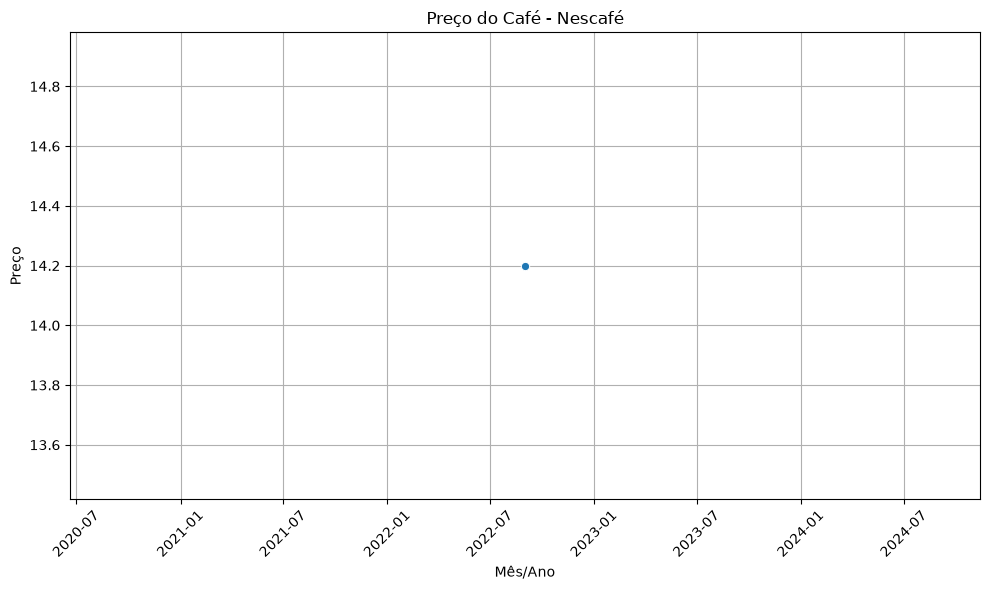

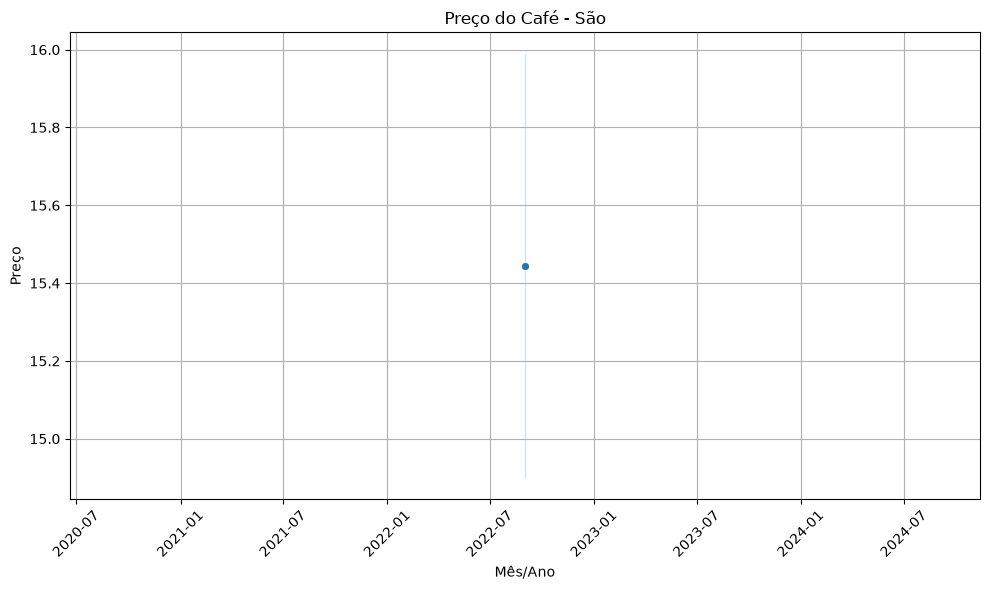

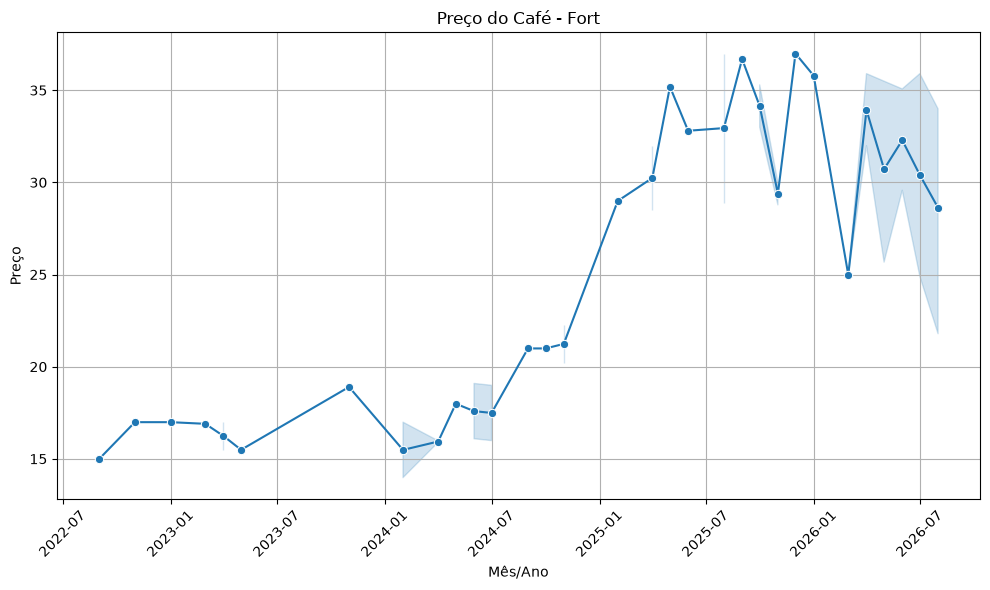

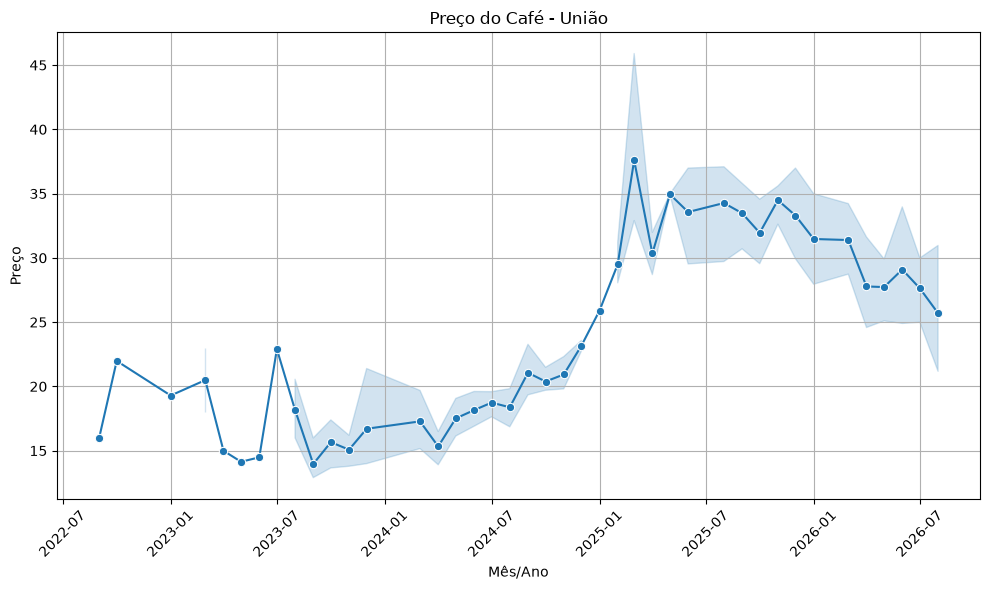

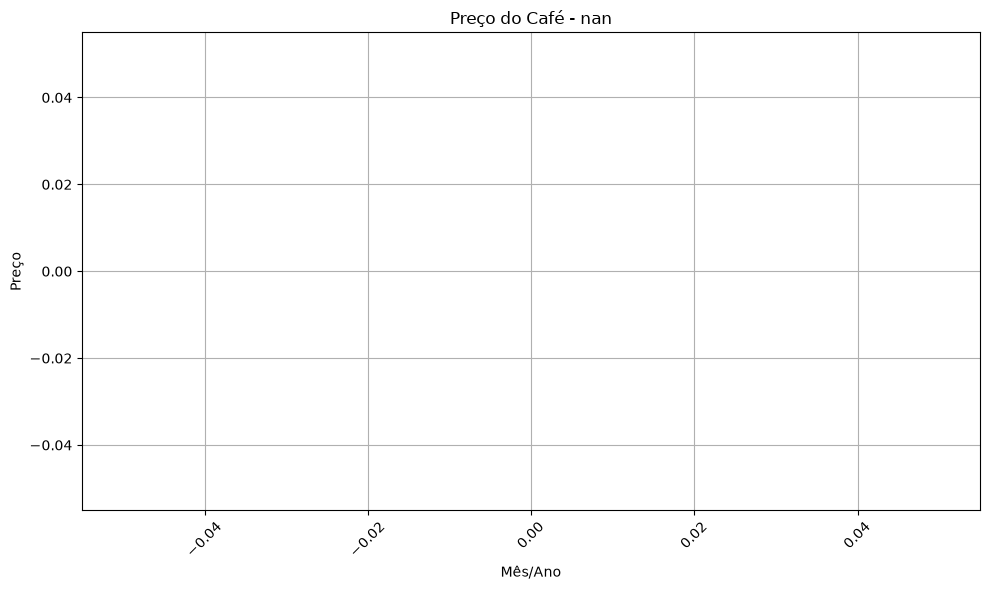

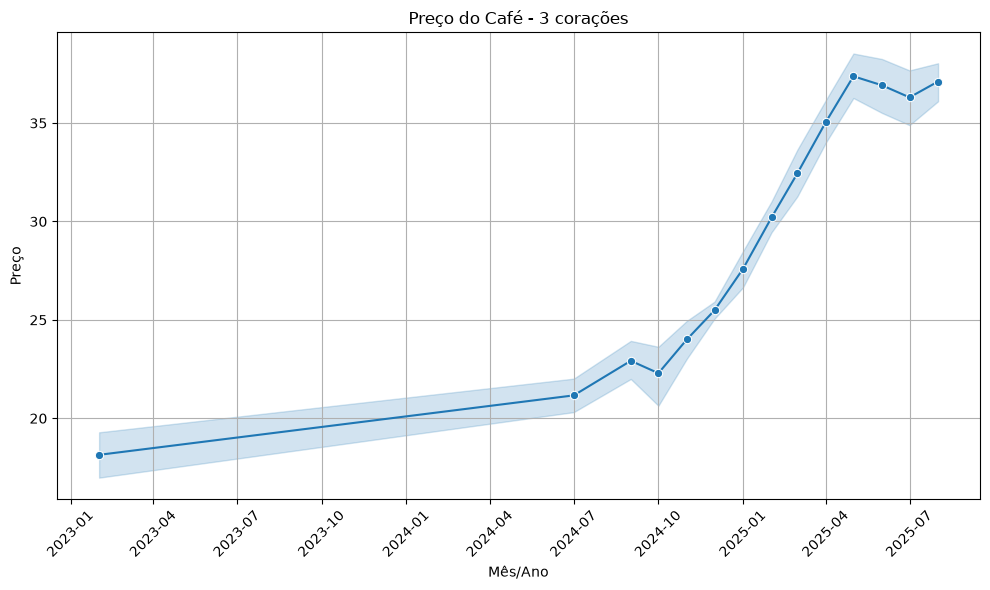

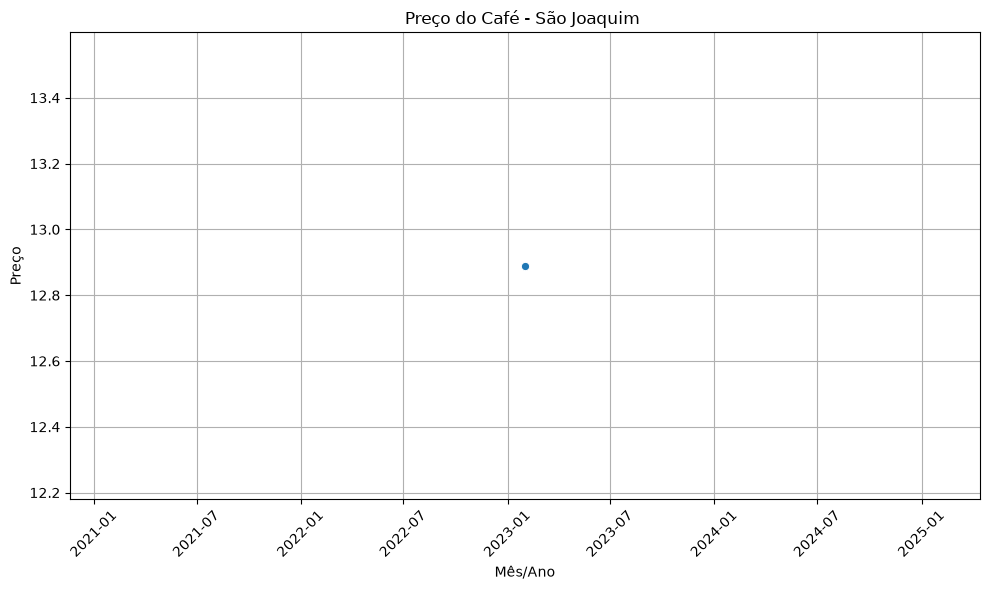

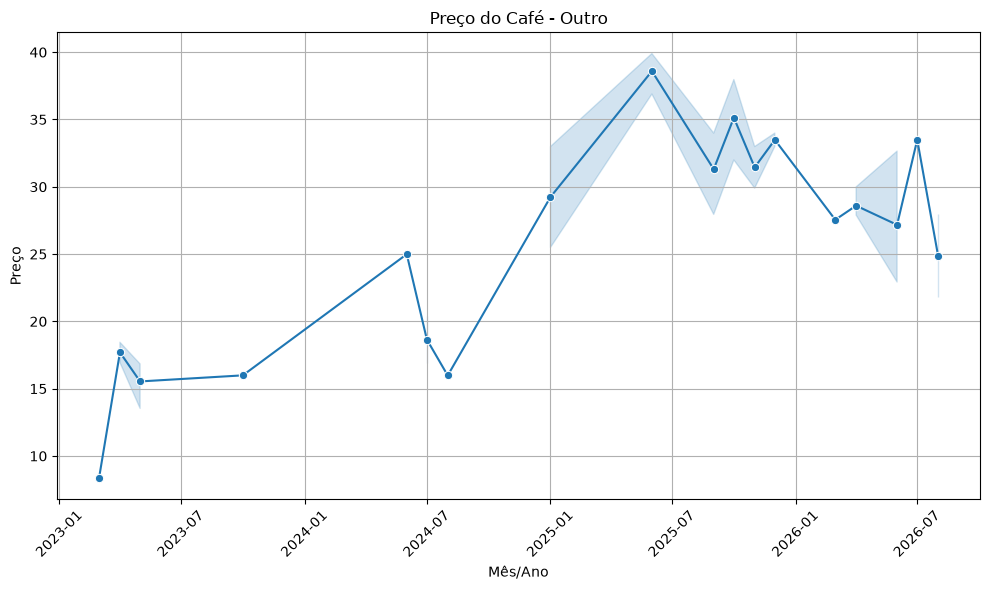

In [22]:
plotar_grafico_por_cada_marca(df_cafe, df_cafe['Marca'].unique())

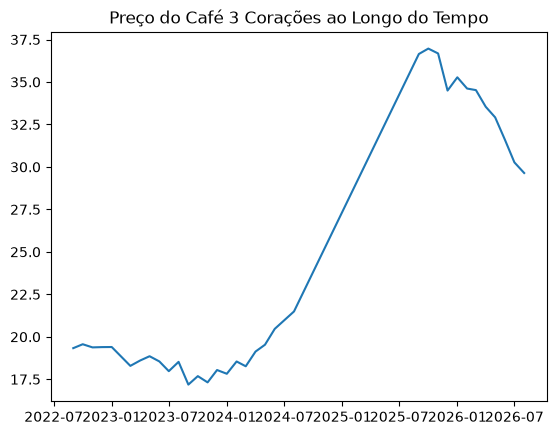

In [16]:

df_3coracoes = df_3coracoes.groupby('Mes_Ano_Data', as_index=False)[['Preco', 'PPK']].mean()
plt.plot(df_3coracoes['Mes_Ano_Data'], df_3coracoes['Preco'])
plt.title('Preço do Café 3 Corações ao Longo do Tempo')
plt.show()

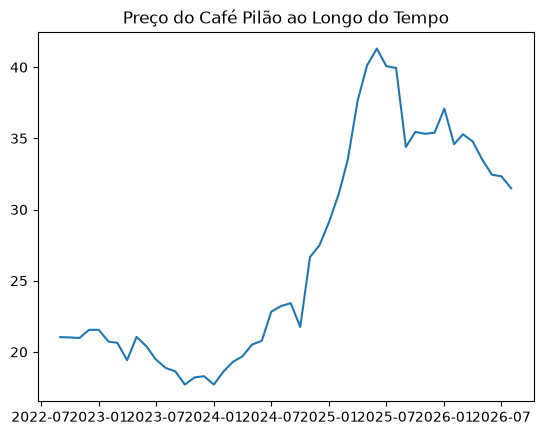

In [15]:

df_pilao = df_pilao.groupby('Mes_Ano_Data', as_index=False)[['Preco', 'PPK']].mean()
plt.plot(df_pilao['Mes_Ano_Data'], df_pilao['Preco'])
plt.title('Preço do Café Pilão ao Longo do Tempo')
plt.show()

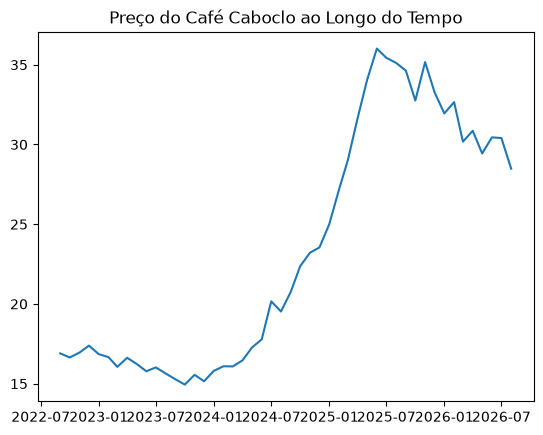

In [14]:

df_caboclo = df_caboclo.groupby('Mes_Ano_Data', as_index=False)[['Preco', 'PPK']].mean()
plt.plot(df_caboclo['Mes_Ano_Data'], df_caboclo['Preco'])
plt.title('Preço do Café Caboclo ao Longo do Tempo')
plt.show()

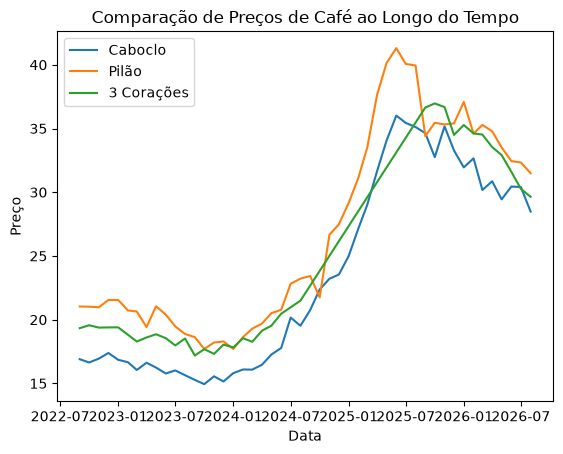

In [17]:
plt.plot(df_caboclo['Mes_Ano_Data'], df_caboclo['Preco'], label='Caboclo')
plt.plot(df_pilao['Mes_Ano_Data'], df_pilao['Preco'], label='Pilão')
plt.plot(df_3coracoes['Mes_Ano_Data'], df_3coracoes['Preco'], label='3 Corações')
plt.title('Comparação de Preços de Café ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Preço')
plt.legend()
plt.show()

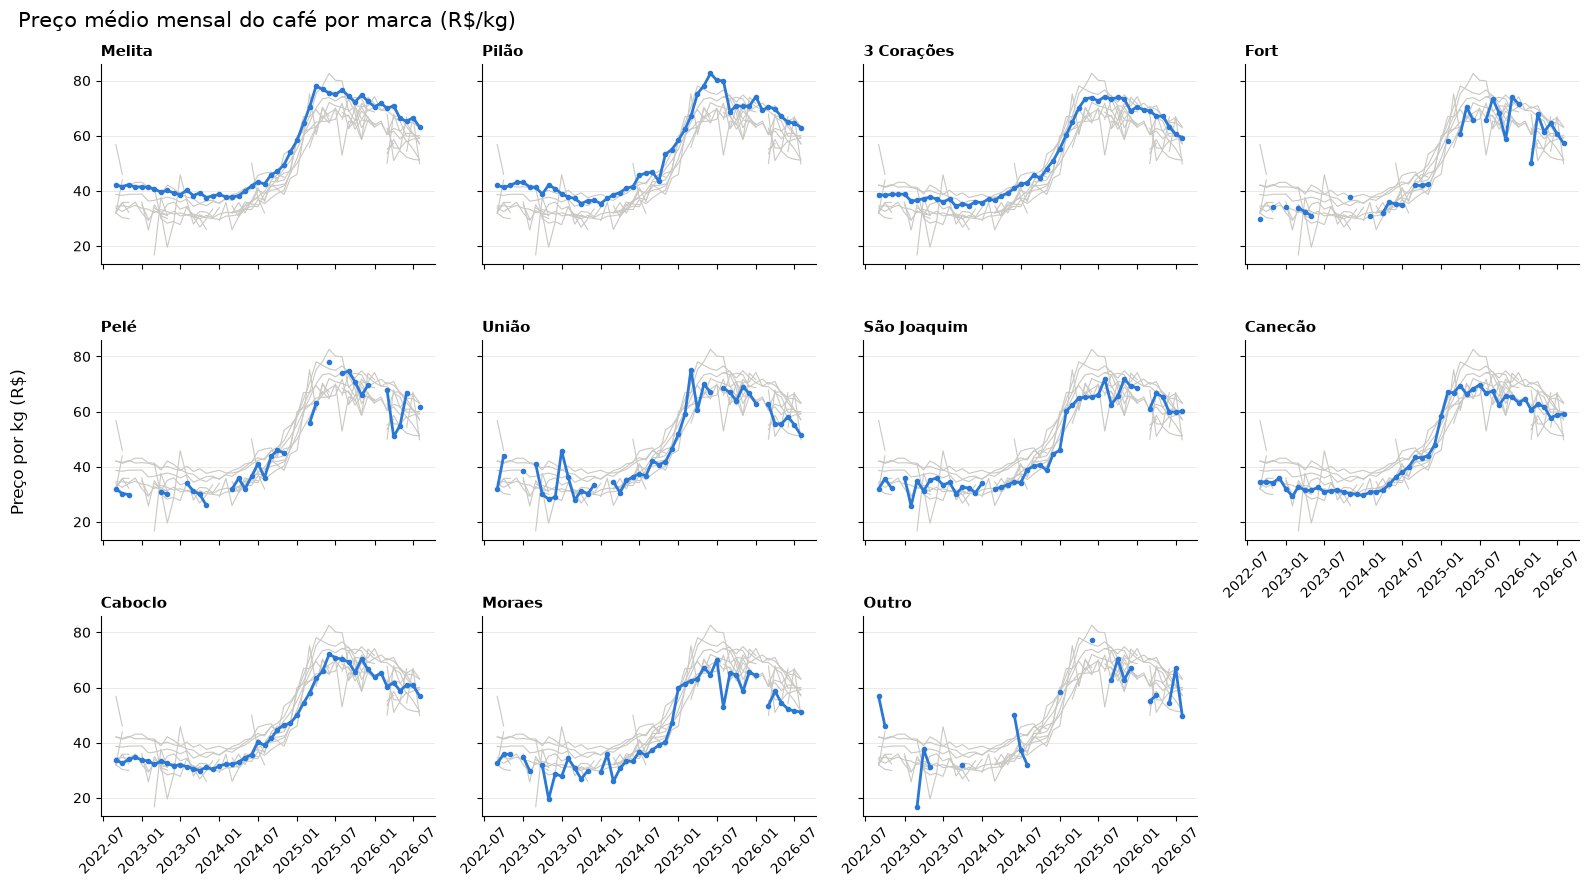

In [20]:
# Padroniza os nomes das marcas (espaços sobrando, maiúsculas/minúsculas, registros incompletos)
marca = df_cafe['Marca'].str.strip().str.title()
marca = marca.replace({'São': 'São Joaquim', 'Nescafé': 'Outro'}).fillna('Outro')

# Média mensal do preço por kg (PPK) de cada marca: uma coluna por marca, uma linha por mês
cafe_mensal = (
    df_cafe.assign(Marca=marca)
    .groupby(['Mes_Ano_Data', 'Marca'])['PPK']
    .mean()
    .unstack('Marca')
)

# Ordena da marca mais cara para a mais barata, deixando "Outro" por último
ordem = cafe_mensal.drop(columns='Outro').mean().sort_values(ascending=False).index.tolist() + ['Outro']

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for ax, nome in zip(axes.flat, ordem):
    # Todas as marcas em cinza como referência, com a marca do painel em destaque
    ax.plot(cafe_mensal.index, cafe_mensal, color='#c9c8c2', linewidth=0.8)
    ax.plot(cafe_mensal.index, cafe_mensal[nome], color='#2a78d6', linewidth=2, marker='o', markersize=3)
    ax.set_title(nome, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', color='#e8e7e2', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', rotation=45)

# Remove os painéis que sobraram na grade e devolve o eixo de datas ao painel logo acima
for ax in axes.flat[len(ordem):]:
    ax.remove()
axes[1, 3].tick_params(axis='x', labelbottom=True)

fig.suptitle('Preço médio mensal do café por marca (R$/kg)', x=0.01, ha='left', fontsize=15)
fig.supylabel('Preço por kg (R$)', x=0.005)
fig.tight_layout(rect=(0.015, 0, 1, 1))
plt.show()

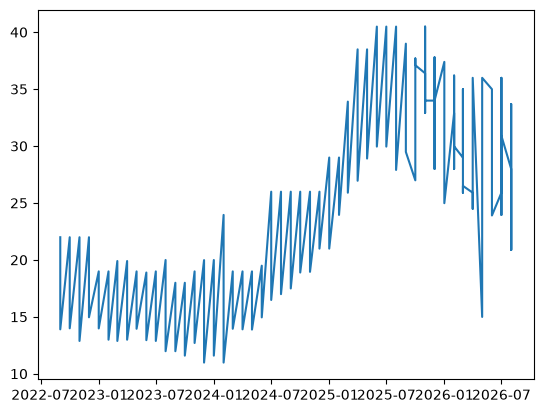

In [27]:
plt.plot(x, y)
plt.show()

In [4]:
# dividir por produto
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
             'Pão Francês',                    'Óleo',
                  'Açúcar',        'Farinha de Trigo',
                  'Feijão',            'Banana Prata',
                   'Leite',                  'Tomate',
                  'Batata',           'Banana Nanica',
       'Carne Bovina Acem',            'Frango Peito',
      'Carne Suína Pernil',        'Frango Sobrecoxa',
                     'Ovo',       'Macarrão com Ovos',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra',                 'Farinha',
                'Macarrão',              'Carne Acem',
        'Carne Coxão Mole',                     'Pão',
            'Carne Pernil',                  'Pernil']
Length: 30, dtype: str